# 0: Imports and configuration
Load all required libraries, define dataset paths, parameters, and create output folders.

In [ ]:
# Section 1: Imports and configuration
import os
import requests
import zipfile
from pathlib import Path
from tqdm import tqdm
import random
import shutil
import xml.etree.ElementTree as ET
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm


# --- CONFIGURATION ---
DATA_ROOT = "dataset"
OUTPUT_DIR = "vehicle_dataset"

IMAGE_SIZE = (960, 540)

MAX_IMAGES = 1500
TRAIN_RATIO = 0.7
VAL_RATIO = 0.2
TEST_RATIO = 0.1
SUBSAMPLE_RATE = 20
SEED = 42

random.seed(SEED)

# Create folders
for split in ["train", "val", "test"]:
    os.makedirs(os.path.join(OUTPUT_DIR, "images", split), exist_ok=True)
    os.makedirs(os.path.join(OUTPUT_DIR, "labels", split), exist_ok=True)

print("Setup done")

Setup done


# 1:  Download UA-DETRAC dataset from OneDrive
Download the dataset from OneDrive into the configured folder and extract the files for processing.

In [12]:
# Section 2: Smart Download UA-DETRAC (only if not exists)
urls = {
    "DETRAC-Train-Annotations-XML.zip": "YOUR_ONEDRIVE_DIRECT_LINK_1",
    "DETRAC-Test-Annotations-XML.zip": "YOUR_ONEDRIVE_DIRECT_LINK_2",
    "DETRAC-train-data.zip": "YOUR_ONEDRIVE_DIRECT_LINK_3",
    "DETRAC-test-data.zip": "YOUR_ONEDRIVE_DIRECT_LINK_4",
}

EXPECTED_FOLDERS = [
    "DETRAC-Train-Annotations-XML",
    "DETRAC-Test-Annotations-XML",
    "DETRAC-Images",
]


def dataset_exists():
    for folder in EXPECTED_FOLDERS:
        if not os.path.exists(os.path.join(DATA_ROOT, folder)):
            return False
    return True


def download_file(url, dest_path):
    response = requests.get(url, stream=True)
    total_size = int(response.headers.get("content-length", 0))
    with open(dest_path, "wb") as f, tqdm(
        desc=os.path.basename(dest_path),
        total=total_size,
        unit="iB",
        unit_scale=True,
        unit_divisor=1024,
    ) as bar:
        for data in response.iter_content(chunk_size=1024):
            size = f.write(data)
            bar.update(size)


os.makedirs(DATA_ROOT, exist_ok=True)

if not dataset_exists():
    for filename, url in urls.items():
        zip_path = os.path.join(DATA_ROOT, filename)

        if not os.path.exists(zip_path):
            download_file(url, zip_path)

        extract_flag = False

        if "Annotations" in filename:
            folder_name = filename.replace(".zip", "")
            if not os.path.exists(os.path.join(DATA_ROOT, folder_name)):
                extract_flag = True
        elif "data" in filename:
            if not os.path.exists(os.path.join(DATA_ROOT, "DETRAC-Images")):
                extract_flag = True

        if extract_flag:
            with zipfile.ZipFile(zip_path, "r") as zip_ref:
                zip_ref.extractall(DATA_ROOT)

# 2: Coordinate Normalization Function
This function converts the UA-DETRAC XML pixel coordinates into the normalized $0.0$ to $1.0$ format required by YOLO.

In [13]:
# Section 2: Convert (x, y, w, h) pixels to YOLO normalized format
def convert_to_yolo(bbox, w_img, h_img):
    """
    bbox: (left, top, width, height) in pixels
    returns: (x_center, y_center, width, height) normalized 0-1
    """
    dw = 1.0 / w_img
    dh = 1.0 / h_img
    x_center = (bbox[0] + bbox[2] / 2.0) * dw
    y_center = (bbox[1] + bbox[3] / 2.0) * dh
    w = bbox[2] * dw
    h = bbox[3] * dh
    return (x_center, y_center, w, h)

# 3: Processing All Sets
This is the main logic. It processes the Train folder (splitting it into Train/Val) and the Test folder separately.

In [14]:
def collect_samples():
    samples = []

    xml_dirs = [
        os.path.join(DATA_ROOT, "DETRAC-Train-Annotations-XML"),
        os.path.join(DATA_ROOT, "DETRAC-Test-Annotations-XML"),
    ]

    img_dir = os.path.join(DATA_ROOT, "DETRAC-Images")

    for xml_dir in xml_dirs:
        xml_files = list(Path(xml_dir).glob("*.xml"))

        for xml_file in xml_files:
            tree = ET.parse(xml_file)
            root = tree.getroot()
            seq_name = root.get("name")

            for frame in root.findall("frame"):
                frame_num = int(frame.get("num"))

                if frame_num % SUBSAMPLE_RATE != 0:
                    continue

                img_name = f"img{frame_num:05d}.jpg"
                img_path = os.path.join(img_dir, seq_name, img_name)

                if not os.path.exists(img_path):
                    continue

                target_list = frame.find("target_list")
                if target_list is None or len(target_list.findall("target")) == 0:
                    continue

                samples.append((xml_file, seq_name, frame_num, img_path))

    print(f"Collected {len(samples)} valid samples")
    return samples


def select_samples(samples):
    if len(samples) < MAX_IMAGES:
        raise ValueError(f"Not enough samples: {len(samples)}")

    random.shuffle(samples)
    selected = samples[:MAX_IMAGES]

    print(f"Selected {len(selected)} samples")
    return selected


def split_samples(samples):
    total = len(samples)

    train_end = int(total * TRAIN_RATIO)
    val_end = train_end + int(total * VAL_RATIO)

    split_data = {
        "train": samples[:train_end],
        "val": samples[train_end:val_end],
        "test": samples[val_end:],
    }

    print(f"Train: {len(split_data['train'])}")
    print(f"Val: {len(split_data['val'])}")
    print(f"Test: {len(split_data['test'])}")

    return split_data

def process_and_save(split_data):
    total = 0

    for split, samples in split_data.items():
        for xml_file, seq_name, frame_num, img_path in samples:

            tree = ET.parse(xml_file)
            root = tree.getroot()

            frame = root.find(f".//frame[@num='{frame_num}']")
            if frame is None:
                continue

            img_out = os.path.join(
                OUTPUT_DIR, "images", split,
                f"{seq_name}_{frame_num:05d}.jpg"
            )

            label_out = os.path.join(
                OUTPUT_DIR, "labels", split,
                f"{seq_name}_{frame_num:05d}.txt"
            )

            shutil.copy(img_path, img_out)

            lines = []
            target_list = frame.find("target_list")

            for target in target_list.findall("target"):
                box = target.find("box")
                if box is None:
                    continue

                bbox = (
                    float(box.get("left")),
                    float(box.get("top")),
                    float(box.get("width")),
                    float(box.get("height")),
                )

                x, y, w, h = convert_to_yolo(
                    bbox, IMAGE_SIZE[0], IMAGE_SIZE[1]
                )

                lines.append(f"0 {x:.6f} {y:.6f} {w:.6f} {h:.6f}")

            # double safety
            if len(lines) == 0:
                continue

            with open(label_out, "w") as f:
                f.write("\n".join(lines))

            total += 1

    print(f"Final dataset size: {total}")
    
def process_dataset():
    samples = collect_samples()
    selected = select_samples(samples)
    split_data = split_samples(selected)
    process_and_save(split_data)

# 4: Random Verification (Visual Check)
This cell will display a random image from your new dataset with the bounding boxes drawn on it. If the boxes fit the cars perfectly, you are ready to train.

In [15]:
def verify_output(split="train", n=10):
    train_images = list(Path(f"{OUTPUT_DIR}/images/{split}").glob("*.jpg"))
    if not train_images:
        print("No images found. Run process_dataset() first.")
        return

    # Pick n random images
    sample_images = random.sample(train_images, min(n, len(train_images)))

    for img_path in sample_images:
        lbl_path = str(img_path).replace("images", "labels").replace(".jpg", ".txt")
        img = cv2.imread(str(img_path))
        h, w, _ = img.shape

        if os.path.exists(lbl_path):
            with open(lbl_path, "r") as f:
                for line in f.readlines():
                    _, x, y, bw, bh = map(float, line.split())
                    x1 = int((x - bw / 2) * w)
                    y1 = int((y - bh / 2) * h)
                    x2 = int((x + bw / 2) * w)
                    y2 = int((y + bh / 2) * h)
                    cv2.rectangle(img, (x1, y1), (x2, y2), (0, 255, 0), 2)

        plt.figure(figsize=(12, 8))
        plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        plt.axis("off")
        plt.title(f"Sanity Check: {img_path.name}")
        plt.show()

# 5: Run Preprocessing

In [16]:
# Section 5: Run preprocessing and verify
process_dataset()

Collected 6879 valid samples
Selected 1500 samples
Train: 1050
Val: 300
Test: 150
Final dataset size: 1500


# Verify output

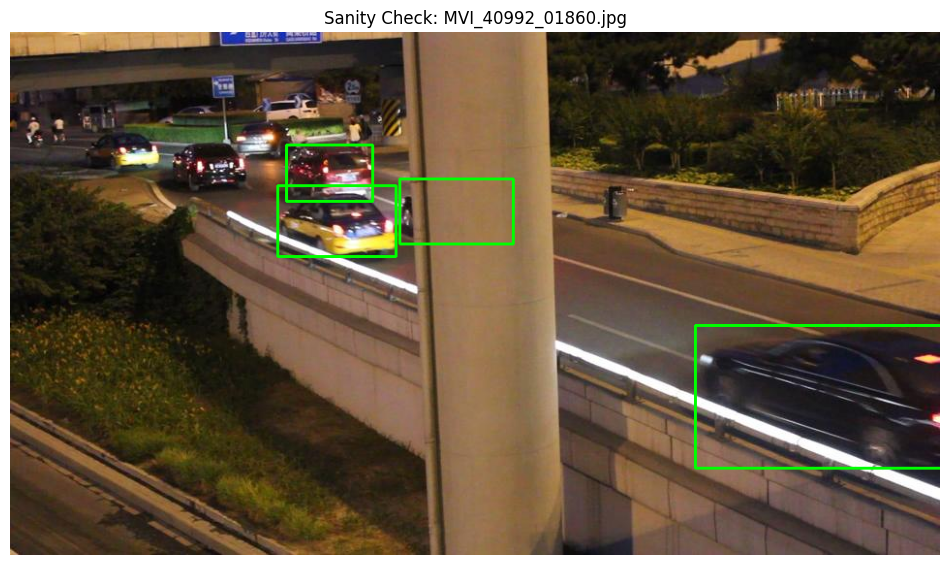

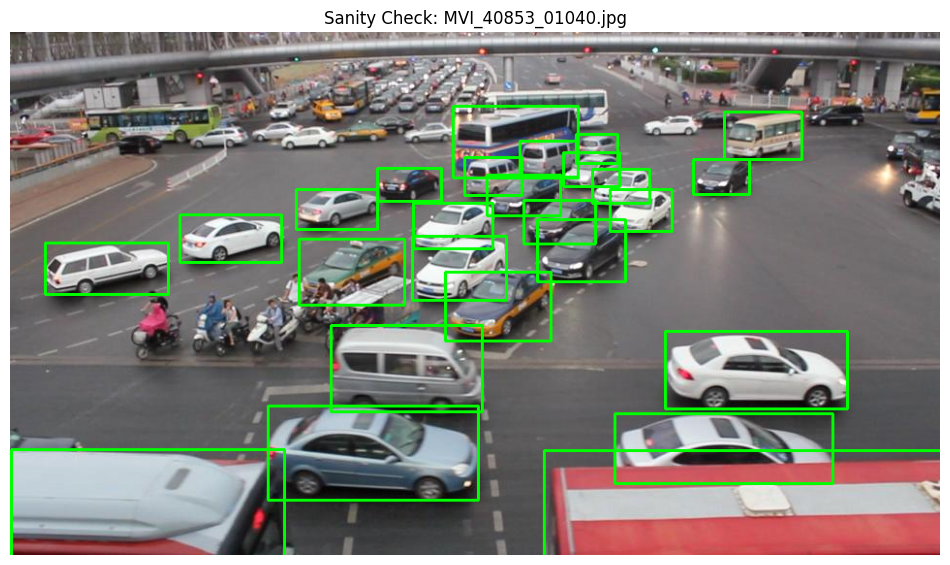

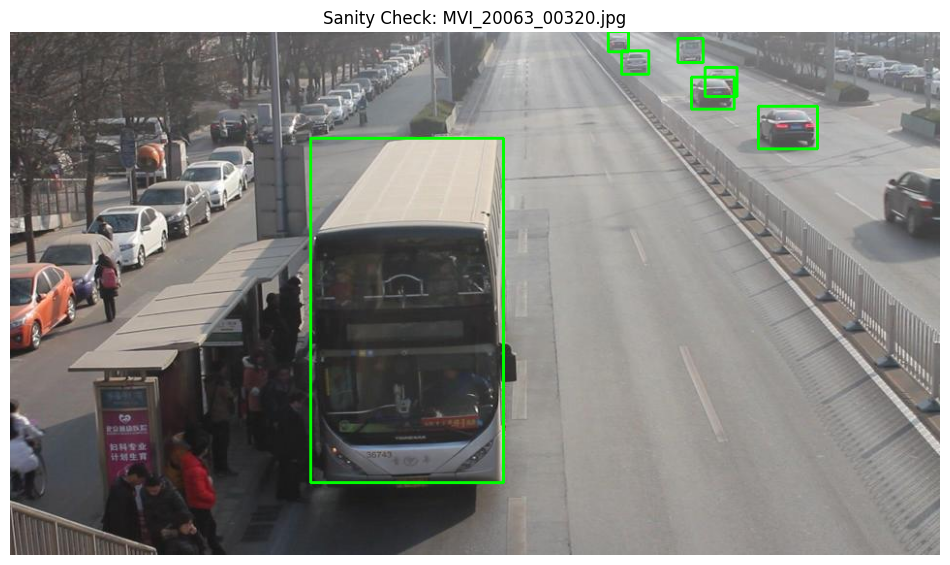

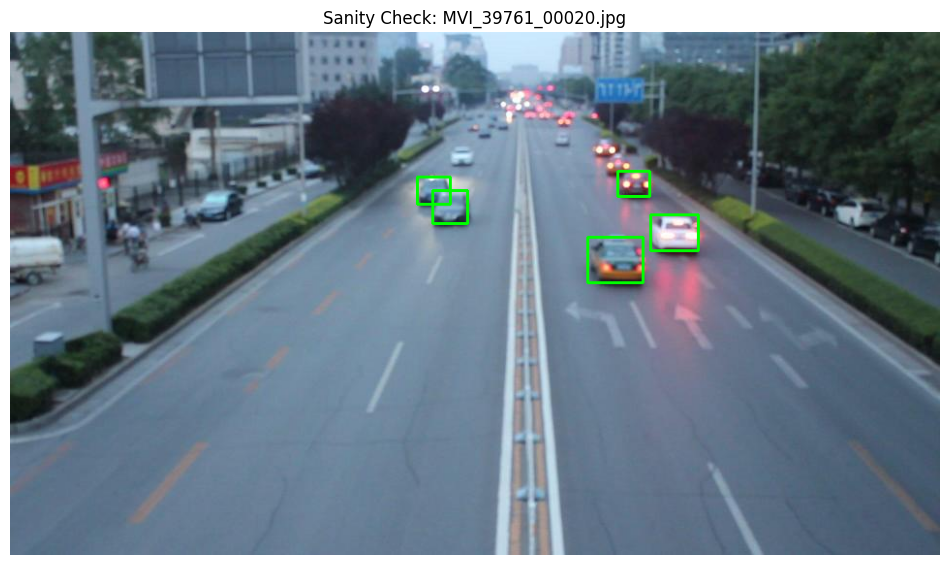

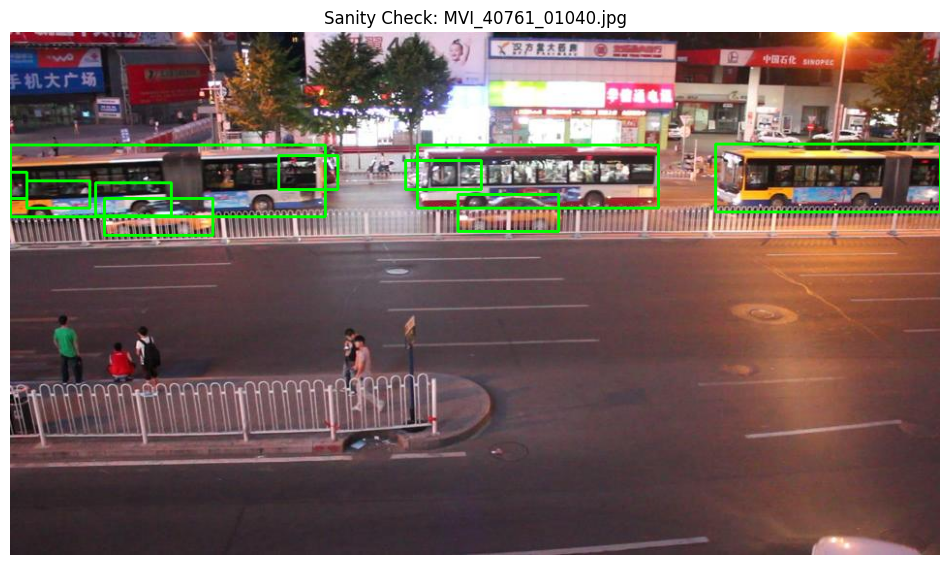

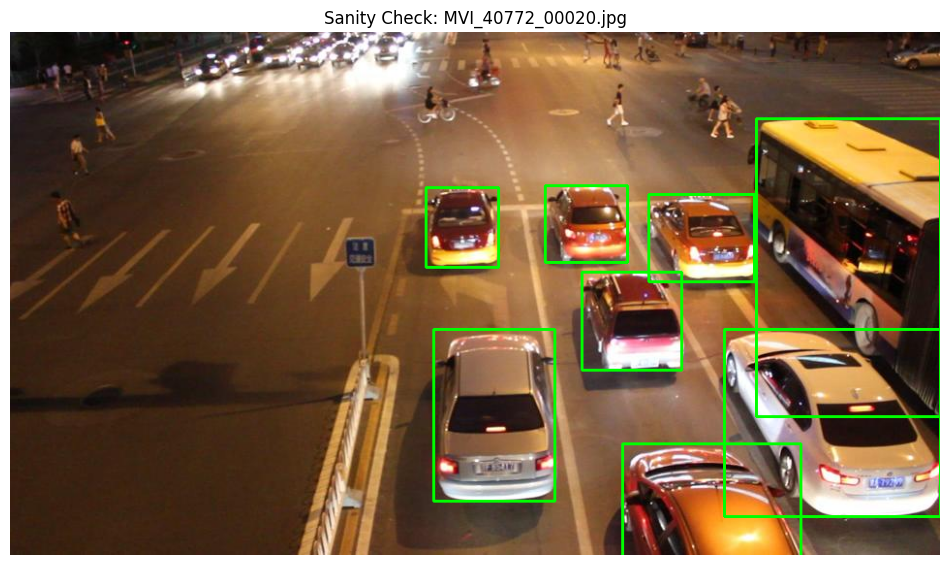

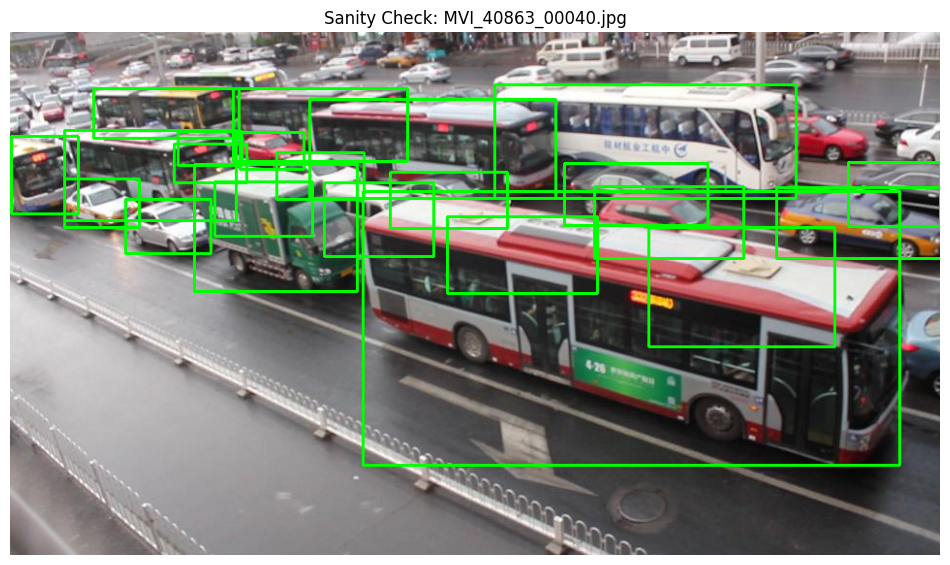

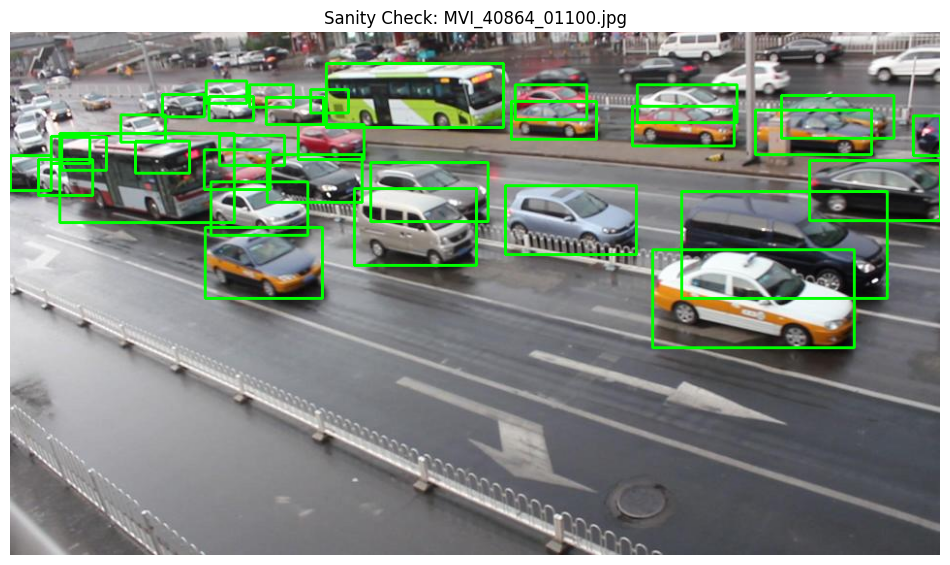

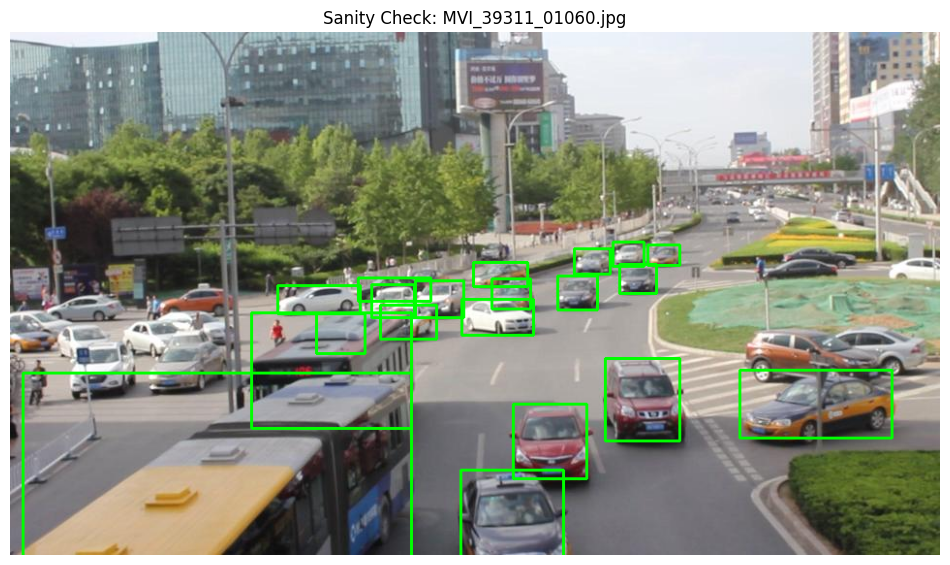

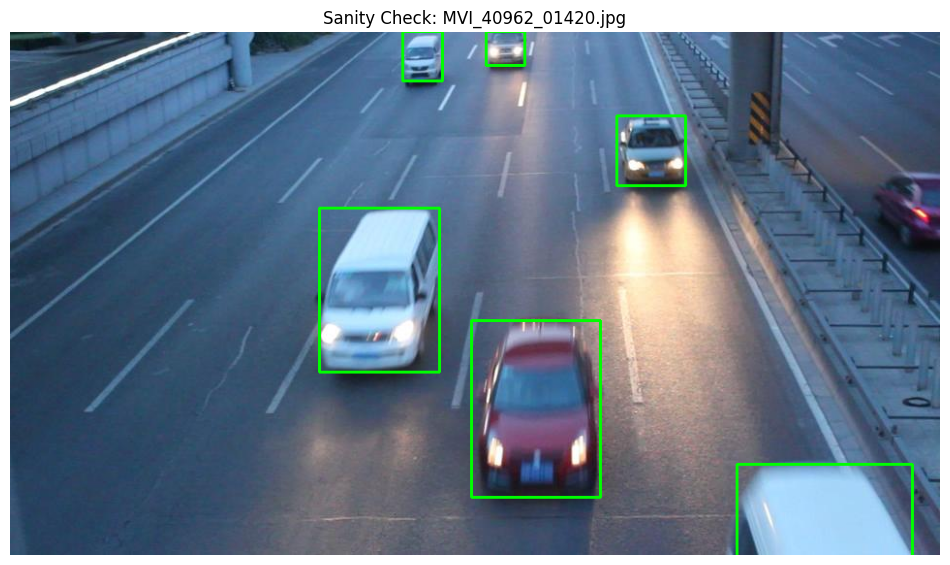

In [17]:
verify_output("train")